In [ ]:
import pandas as pd
import numpy as np

In [5]:
# load the data
df = pd.read_csv('./data/SECTION_C1.csv')

C:\Users\user\AppData\Local\Temp\ipykernel_17684\4133478529.py:2: DtypeWarning: Columns (122: C043) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('./data/SECTION_C1.csv')


In [6]:
# check the shape of the data
print(df.shape)

(5706, 280)


In [7]:
# find out how the data looks like 
df.describe()

,PROVINCE,DISTRICT,HI04,Cluster,HI05,HH_WT,TYPEHH,C003,C012,C012_OTHER,...,C171,C172,C173,C174,C175,C176,C177,hhid,camp,ref_weight
count,5706.000000,5706.000000,5706.000000,5706.000000,5706.000000,5006.000000,5706.000000,3057.000000,2649.000000,43.000000,...,5706.000000,5706.000000,4701.000000,4701.000000,1522.000000,1522.000000,4701.000000,5.706000e+03,700.000000,700.000000
mean,3.061514,34.058885,1.642832,159.666316,9.849982,595.212459,1.475289,47.083415,13.577199,3.813953,...,44.472660,1.591833,1.677515,1.323761,1.440210,1130.274639,1.682195,3.565565e+08,2.985714,38.100000
std,1.425043,14.629112,0.479207,91.851504,5.451203,696.317431,0.775955,149.642175,71.786500,2.830580,...,53.136571,1.259661,0.467477,0.467960,0.711075,763.811237,0.465673,1.553872e+08,1.418182,34.939725
min,1.000000,11.000000,1.000000,1.000000,1.000000,4.944995,1.000000,1.000000,1.000000,1.000000,...,1.000000,0.000000,1.000000,1.000000,1.000000,100.000000,1.000000,1.101001e+08,1.000000,18.007936
25%,2.000000,23.000000,1.000000,80.000000,5.000000,87.080700,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,800.000000,1.000000,2.380012e+08,2.000000,18.555555
50%,3.000000,32.000000,2.000000,160.000000,10.000000,288.145400,1.000000,2.000000,1.000000,3.000000,...,5.000000,1.000000,2.000000,1.000000,1.000000,800.000000,2.000000,3.360003e+08,3.000000,21.607143
75%,5.000000,51.000000,2.000000,239.000000,14.000000,1016.903386,2.000000,5.000000,1.000000,5.000000,...,111.000000,2.000000,2.000000,2.000000,2.000000,1600.000000,2.000000,5.339014e+08,4.000000,22.381945
max,5.000000,57.000000,2.000000,319.000000,22.000000,18527.360000,3.000000,555.000000,555.000000,11.000000,...,111.000000,10.000000,2.000000,2.000000,8.000000,6400.000000,2.000000,6.019018e+08,5.000000,106.034248


In [8]:
# checking to see what each row represents
print(len(df))
print(df.nunique())

5706
PROVINCE         5
DISTRICT        30
HI04             2
Cluster        319
HI05            22
              ... 
C176            34
C177             2
hhid          5706
camp             5
ref_weight       5
Length: 280, dtype: int64


Each row represents a household

In [9]:
#checking how many households have a particular unit (hours or minutes)
df['C032B_UNITY'].value_counts()

C032B_UNITY
2.0    1314
1.0     468
Name: count, dtype: int64

In [10]:
# checking which rows have a certain value
count_connected = ((df['C002'] == 1) & (df['C031B'] == 111)).sum()
print('The number of households that are connected to the gird but have no outages')
print(count_connected)


The number of households that are connected to the gird but have no outages
570


In [11]:
df['C032B'].value_counts()

C032B
5.0      769
888.0    278
30.0     272
10.0     180
20.0     153
60.0     100
15.0      99
120.0     74
40.0      51
45.0      26
25.0      26
111.0     19
90.0      17
50.0       8
35.0       7
Name: count, dtype: int64

In [ ]:
# checking how many 888 values are in C032B
dont_know = df[df['C032B'] == 888]
print(dont_know['C032B_UNITY'].value_counts(dropna=False))

print(dont_know[['C002', 'C031B']].value_counts(dropna=False))

C032B_UNITY
NaN    278
Name: count, dtype: int64
C031B
888.0    243
1.0       16
2.0       10
3.0        5
10.0       1
7.0        1
5.0        1
4.0        1
Name: count, dtype: int64


In [13]:
# Find records where C032B says "None"
none_duration = df[df["C032B"] == 111].copy()

# Check their grid connection and reported outage count
print(none_duration[["C002", "C031B", "C032B", "C032B_UNITY"]]
    .value_counts(dropna=False))

print("\nC031B values:")
print(none_duration["C031B"].value_counts(dropna=False))

C002  C031B  C032B  C032B_UNITY
1     1.0    111.0  NaN            11
      2.0    111.0  NaN             5
      3.0    111.0  NaN             3
Name: count, dtype: int64

C031B values:
C031B
1.0    11
2.0     5
3.0     3
Name: count, dtype: int64


In [15]:
# the rows we keep for the target
outage_rows = df[(df['C002'] == 1) & (df['C032B_UNITY'].notna())]
print(len(outage_rows))
#  what values does C031B take inside this group?
print(outage_rows['C031B'].value_counts(dropna=False).sort_index())

1782
C031B
1.0     944
2.0     490
3.0     211
4.0      51
5.0      32
6.0      19
7.0      19
8.0       5
9.0       1
10.0     10
Name: count, dtype: int64


In [20]:
raw_duration = outage_rows.groupby('C032B_UNITY')['C032B'].agg(['count', 'min', 'max'])
print(raw_duration)

             count  min    max
C032B_UNITY                   
1.0            468  5.0  120.0
2.0           1314  5.0  120.0


In [22]:
Hour_rows = df[(df['C002'] == 1) & (df['C032B_UNITY'] == 2)]
print(Hour_rows['C032B'].value_counts(dropna=False))

C032B
5.0      354
30.0     268
10.0     162
20.0     148
60.0      98
15.0      93
120.0     73
40.0      47
45.0      26
90.0      17
25.0      13
50.0       8
35.0       7
Name: count, dtype: int64


In [ ]:
target_df = outage_rows.copy()
target_df['outage_duration_minutes'] = np.where(
    target_df["C032B_UNITY"] == 1,
    target_df["C032B"] * 60,
    target_df["C032B"]
)
# cap the values at 300 minutes
target_df['outage_duration_minutes'] = (target_df['outage_duration_minutes'].clip(upper=300))

In [24]:
target = target_df["outage_duration_minutes"]

print("Number of values:", target.count())
print("Missing values:", target.isna().sum())
print("Minimum:", target.min())
print("Maximum:", target.max())
print("Number equal to 300:", (target == 300).sum())

Number of values: 1782
Missing values: 0
Minimum: 5.0
Maximum: 300.0
Number equal to 300: 468


In [25]:
target.describe()

count    1782.00000
mean       98.97587
std       122.47622
min         5.00000
25%        10.00000
50%        30.00000
75%       300.00000
max       300.00000
Name: outage_duration_minutes, dtype: float64

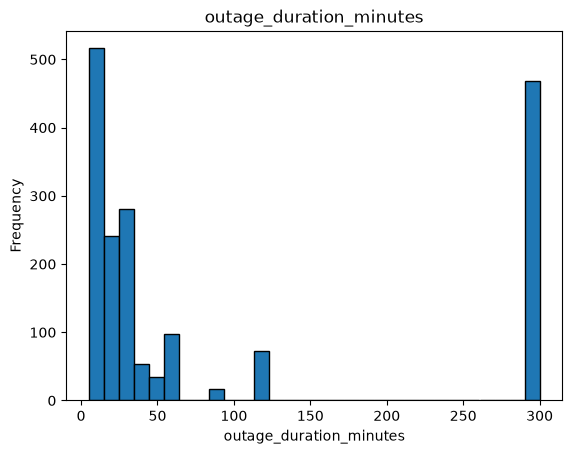

In [ ]:
import matplotlib.pyplot as plt
target.plot.hist(bins=30, edgecolor='black', title='The target')
plt.xlabel('outage_duration_minutes')
plt.show()

the bulk is at the left side of the histogram. It indicates that most of the households have the smaller values that is why the tallest bar is at the left. At 300, the spike pull the mean above the median. The empty gap between 120 and 290 shows that no values fall here because the raw values of the minutes group range from 5 to 120 so they are not converted and 120 is the largest that group can produce. the hours group also has vlaues from 5 to 120 and the lowest it can produce when multiplied by 60 is 300. this is why there is the empty space. the spike is made of the 415 households that recorded 5 hours and the 53 that recorded more than 5 hours but we capped. I capped the values at 300 minutes so that 53 extreme answers wouldn't dominate the MSE.